In [1]:
import os

folder = r"C:\Users\soumi\Desktop\C.elegans Aging Project Data\N2 D1"

print(os.path.exists(folder))

True


In [2]:
import os

folder = r"C:\Users\soumi\Desktop\C.elegans Aging Project Data\N2 D1"

print(os.listdir(folder)[:5])

['N2 day1 image 01.tif', 'N2 day1 image 02.tif', 'N2 day1 image 03.tif', 'N2 day1 image 04.tif', 'N2 day1 image 05.tif']


In [3]:
from skimage.io import imread

file = r"C:\Users\soumi\Desktop\C.elegans Aging Project Data\N2 D1\N2 day1 image 01.tif"

img = imread(file)

print(img.shape)

(135, 411, 717, 3)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [45..20126].


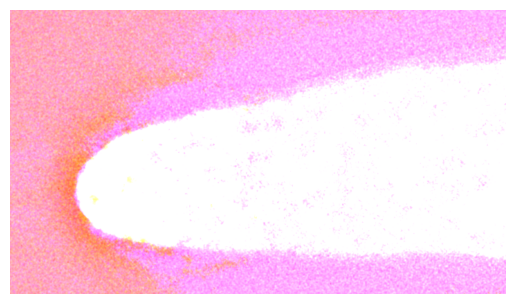

In [4]:
import matplotlib.pyplot as plt

plt.imshow(img[75])
plt.axis("off")
plt.show()

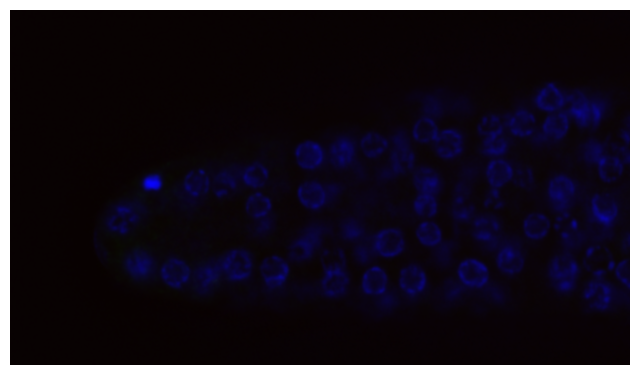

In [5]:
import numpy as np
import matplotlib.pyplot as plt

slice75 = img[75]

slice75 = slice75.astype(float)

slice75 = slice75 / slice75.max()

plt.figure(figsize=(8,6))
plt.imshow(slice75)
plt.axis("off")
plt.show()

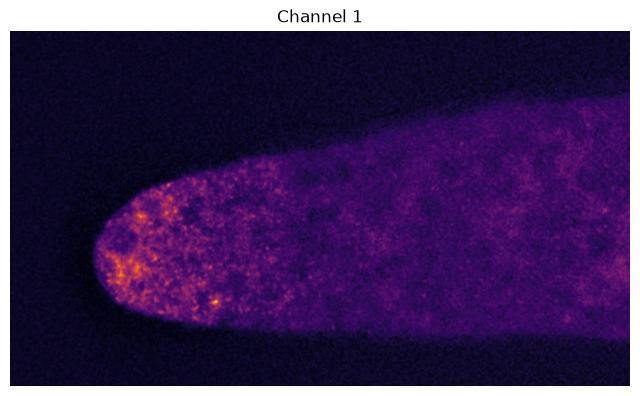

In [6]:
# Channel 1
plt.figure(figsize=(8,6))

plt.imshow(img[75,:,:,1], cmap="inferno")

plt.title("Channel 1")
plt.axis("off")

plt.show()

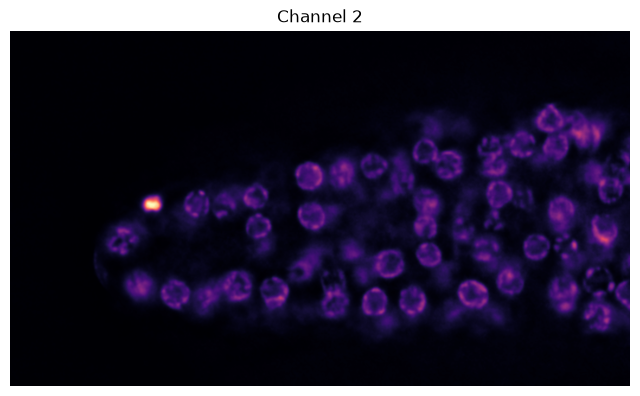

In [7]:
# Channel 2
plt.figure(figsize=(8,6))

plt.imshow(img[75,:,:,2], cmap="magma")

plt.title("Channel 2")
plt.axis("off")

plt.show()

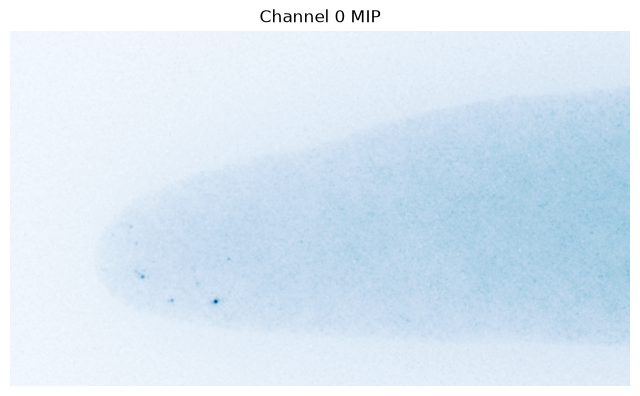

In [8]:
# maximum intensity projection for DAPI
import numpy as np
import matplotlib.pyplot as plt

proj0 = np.max(img[:,:,:,0], axis=0)

plt.figure(figsize=(8,6))
plt.imshow(proj0, cmap="Blues")
plt.title("Channel 0 MIP")
plt.axis("off")
plt.show()

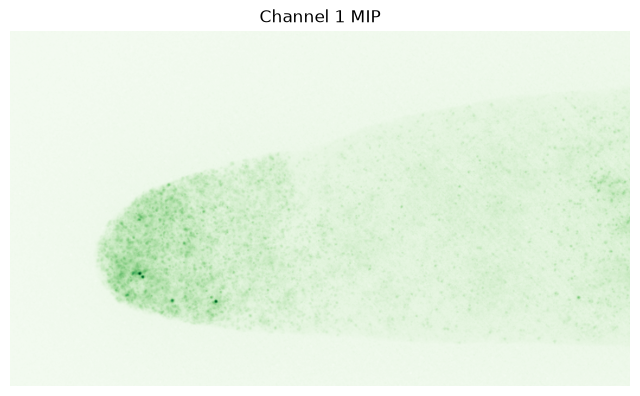

In [9]:
# maximum intensity projection for Channel 1
proj1 = np.max(img[:,:,:,1], axis=0)

plt.figure(figsize=(8,6))
plt.imshow(proj1, cmap="Greens")
plt.title("Channel 1 MIP")
plt.axis("off")
plt.show()

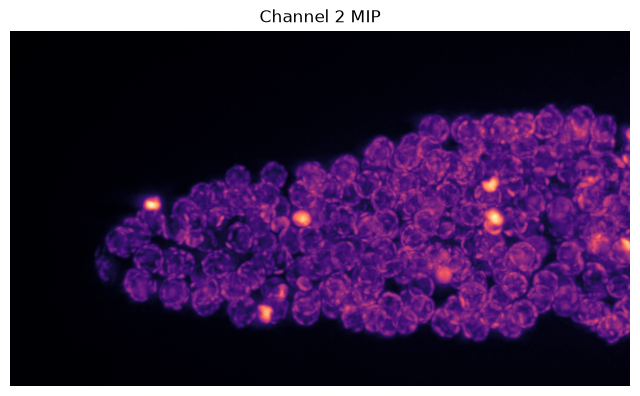

In [10]:
# maximum intensity projection for Channel 2
proj2 = np.max(img[:,:,:,2], axis=0)

plt.figure(figsize=(8,6))
plt.imshow(proj2, cmap="magma")
plt.title("Channel 2 MIP")
plt.axis("off")
plt.show()

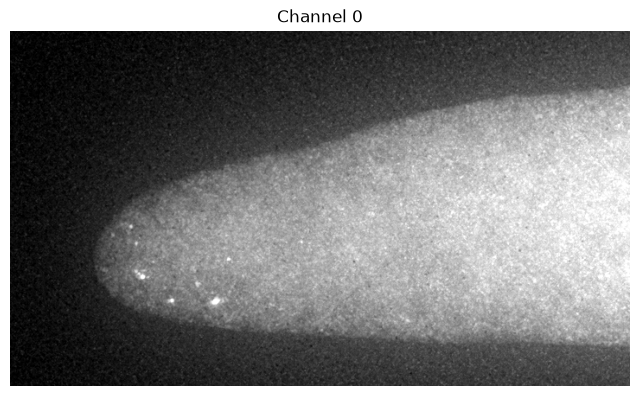

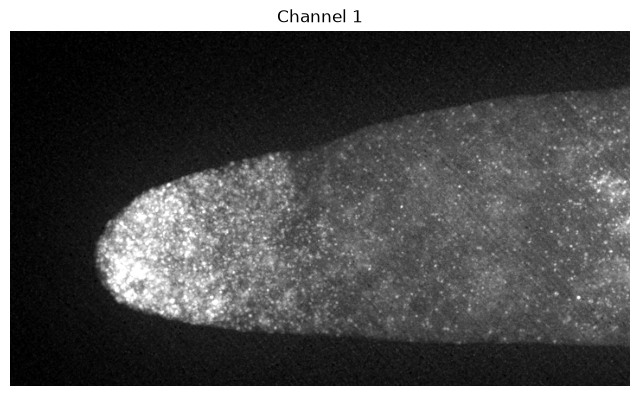

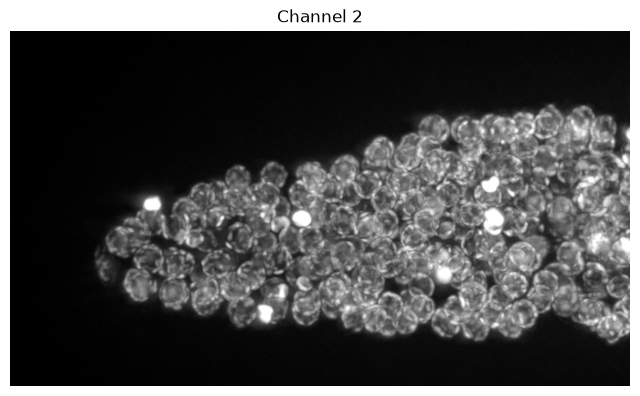

In [11]:
# To improve contrast 
import numpy as np
import matplotlib.pyplot as plt

for c in range(3):
    
    proj = np.max(img[:,:,:,c], axis=0)

    low, high = np.percentile(proj, (1,99.5))

    plt.figure(figsize=(8,6))
    plt.imshow(proj,
               cmap="gray",
               vmin=low,
               vmax=high)

    plt.title(f"Channel {c}")
    plt.axis("off")
    plt.show()

In [12]:
# Measure sygl-1 expression
proj_sygl1 = np.max(img[:,:,:,1], axis=0)

mean_intensity = np.mean(proj_sygl1)

integrated_intensity = np.sum(proj_sygl1)

print("Mean:", mean_intensity)
print("Integrated:", integrated_intensity)

Mean: 316.5298129880178
Integrated: 93277221


In [13]:
# individual RNA spot
from skimage.feature import blob_log

spots = blob_log(
    proj_sygl1,
    min_sigma=1,
    max_sigma=3,
    num_sigma=10,
    threshold=0.001
)

print("Number of spots:", 
len(spots))

Number of spots: 590


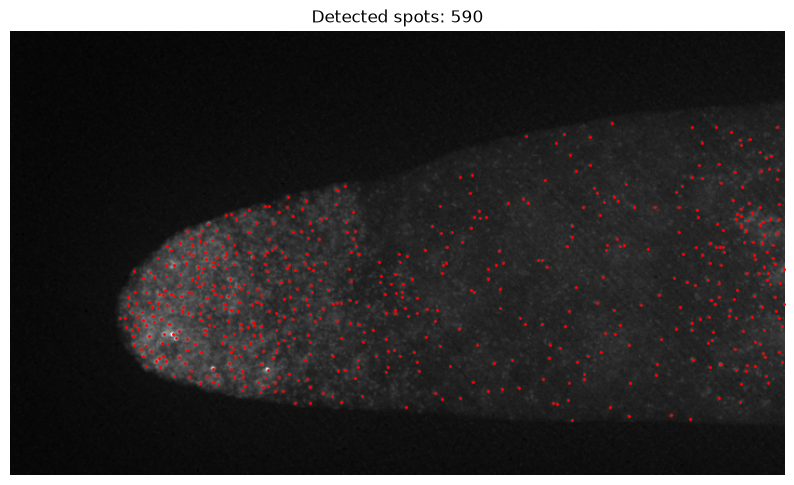

In [14]:
# validating the spot 
plt.figure(figsize=(10,8))

plt.imshow(proj1, cmap="gray")

for y, x, r in spots:
    plt.plot(x, y, 'r.', markersize=2)

plt.title(f"Detected spots: {len(spots)}")
plt.axis("off")

plt.show()

In [15]:
day1_folder = r"C:\Users\soumi\Desktop\C.elegans Aging Project Data\N2 D1"
day4_folder = r"C:\Users\soumi\Desktop\C.elegans Aging Project Data\N2 D4"

In [16]:
import os

day1_files = [f for f in os.listdir(day1_folder) if f.endswith('.tif')]
day4_files = [f for f in os.listdir(day4_folder) if f.endswith('.tif')]

print("Day1:", len(day1_files))
print("Day4:", len(day4_files))

Day1: 28
Day4: 39


In [17]:
import os

print(os.listdir(day4_folder))

['Image1.tif', 'Image10.tif', 'Image11.tif', 'Image12.tif', 'Image13.tif', 'Image14.tif', 'Image15.tif', 'Image16.tif', 'Image17.tif', 'Image18.tif', 'Image19.tif', 'Image2.tif', 'Image20.tif', 'Image21.tif', 'Image23.tif', 'Image24.tif', 'Image25.tif', 'Image26.tif', 'Image27.tif', 'Image28.tif', 'Image29.tif', 'Image3.tif', 'Image30.tif', 'Image31.tif', 'Image32.tif', 'Image33.tif', 'Image34.tif', 'Image35.tif', 'Image36.tif', 'Image37.tif', 'Image38.tif', 'Image39.tif', 'Image4.tif', 'Image40.tif', 'Image41.tif', 'Image5.tif', 'Image7.tif', 'Image8.tif', 'Image9.tif']


In [18]:
from skimage.io import imread
from skimage.feature import blob_log
import numpy as np

def analyze_image(filepath):

    img = imread(filepath)

    # Channel 1 (sygl-1)
    proj = np.max(img[:,:,:,1], axis=0)

    mean_intensity = np.mean(proj)

    integrated_intensity = np.sum(proj)

    spots = blob_log(
        proj,
        min_sigma=1,
        max_sigma=3,
        num_sigma=10,
        threshold=0.001
    )

    spot_count = len(spots)

    return mean_intensity, integrated_intensity, spot_count

In [19]:
file = os.path.join(day1_folder, day1_files[0])

mean_i, integrated_i, spots = analyze_image(file)

print("Mean:", mean_i)
print("Integrated:", integrated_i)
print("Spots:", spots)

Mean: 316.5298129880178
Integrated: 93277221
Spots: 590


In [20]:
import pandas as pd

results = []

In [21]:
# Process Day 1 images

for file in day1_files:

    path = os.path.join(day1_folder, file)

    mean_i, integrated_i, spots = analyze_image(path)

    results.append({
        "Image": file,
        "Age": "Day1",
        "Mean_Intensity": mean_i,
        "Integrated_Intensity": integrated_i,
        "Spot_Count": spots
    })

print("Finished Day 1")

Finished Day 1


In [22]:
len(results)


28

In [23]:
# Process Day 4 images

for file in day4_files:

    path = os.path.join(day4_folder, file)

    mean_i, integrated_i, spots = analyze_image(path)

    results.append({
        "Image": file,
        "Age": "Day4",
        "Mean_Intensity": mean_i,
        "Integrated_Intensity": integrated_i,
        "Spot_Count": spots
    })

print("Finished Day 4")

Finished Day 4


In [24]:
len(results)

67

In [25]:
import pandas as pd

df = pd.DataFrame(results)

df.head()


,Image,Age,Mean_Intensity,Integrated_Intensity,Spot_Count
0,N2 day1 image 01.tif,Day1,316.529813,93277221,590
1,N2 day1 image 02.tif,Day1,319.456577,97249610,859
2,N2 day1 image 03.tif,Day1,313.323811,84823022,802
3,N2 day1 image 04.tif,Day1,321.431752,87064290,510
4,N2 day1 image 05.tif,Day1,293.120213,95255862,595


In [26]:
df.shape


(67, 5)

In [27]:
df.tail()

,Image,Age,Mean_Intensity,Integrated_Intensity,Spot_Count
62,Image41.tif,Day4,217.836516,73096350,1153
63,Image5.tif,Day4,386.412601,151892611,331
64,Image7.tif,Day4,302.327925,117327421,191
65,Image8.tif,Day4,352.377305,125990391,252
66,Image9.tif,Day4,353.878681,124313334,314


In [28]:
df["Age"].value_counts()

Age
Day4    39
Day1    28
Name: count, dtype: int64

In [29]:
df.groupby("Age")[["Spot_Count",
                   "Mean_Intensity",
                   "Integrated_Intensity"]].describe()

Spot_Count                                                               \
          count        mean         std    min    25%    50%     75%     max   
Age                                                                            
Day1       28.0  658.464286  182.485206  389.0  520.0  642.0  743.25  1228.0   
Day4       39.0  731.435897  359.909623  189.0  392.0  745.0  960.00  1384.0   

     Mean_Intensity              ...                          \
              count        mean  ...         75%         max   
Age                              ...                           
Day1           28.0  220.377331  ...  292.845930  321.431752   
Day4           39.0  256.435331  ...  310.244401  507.128741   

     Integrated_Intensity                                                      \
                    count          mean           std         min         25%   
Age                                                                             
Day1                 28.0  7.436044e+07  2.336240e+07  46168759.0  56293667.5   
Day4                 39.0  8.638890e+07  2.887050e+07  51586993.0  65108027.0   

                                            
             50%          75%          max  
Age                                         
Day1  63716527.5   95747839.0  135294928.0  
Day4  74595459.0  105125587.0  151892611.0  

[2 rows x 24 columns]

In [30]:
# split day1 and day4
day1 = df[df["Age"]=="Day1"]

day4 = df[df["Age"]=="Day4"]

In [31]:
# sygl-1 spot detection 
from scipy.stats import ttest_ind

t,p = ttest_ind(
    day1["Spot_Count"],
    day4["Spot_Count"]
)

print("p-value =", p)

p-value = 0.3285719662532312


In [32]:
# mean intensity
t,p = ttest_ind(
    day1["Mean_Intensity"],
    day4["Mean_Intensity"]
)

print("Mean Intensity p-value =", p)

Mean Intensity p-value = 0.05906905506193189


In [33]:
# Integrated intensity
t,p = ttest_ind(
    day1["Integrated_Intensity"],
    day4["Integrated_Intensity"]
)

print("Integrated Intensity p-value =", p)

Integrated Intensity p-value = 0.07377517653674298


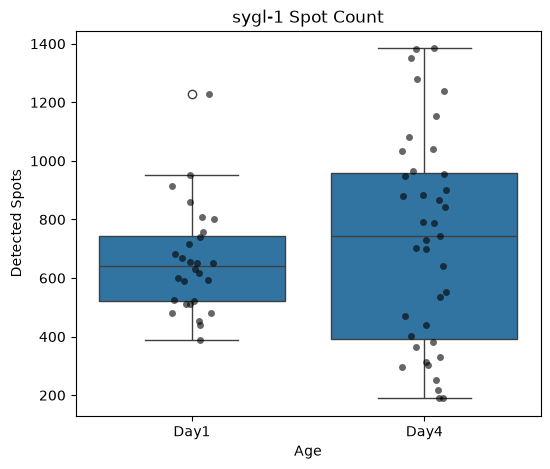

In [34]:
#  Figure 1: Spot Count 
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.boxplot(
    data=df,
    x="Age",
    y="Spot_Count"
)

sns.stripplot(
    data=df,
    x="Age",
    y="Spot_Count",
    color="black",
    alpha=0.6
)

plt.title("sygl-1 Spot Count")
plt.ylabel("Detected Spots")

plt.show()


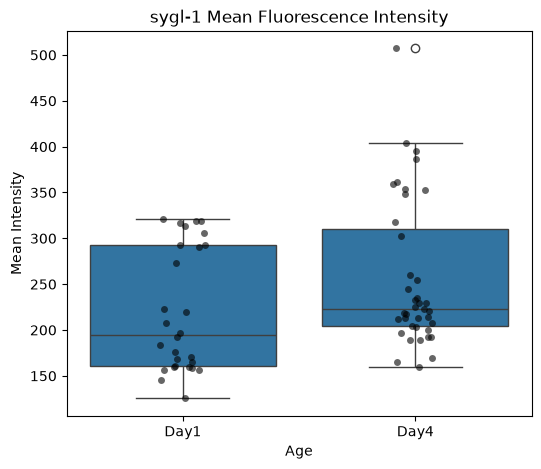

In [35]:
# Figure 2: Mean Intensity
plt.figure(figsize=(6,5))

sns.boxplot(
    data=df,
    x="Age",
    y="Mean_Intensity"
)

sns.stripplot(
    data=df,
    x="Age",
    y="Mean_Intensity",
    color="black",
    alpha=0.6
)

plt.title("sygl-1 Mean Fluorescence Intensity")
plt.ylabel("Mean Intensity")

plt.show()

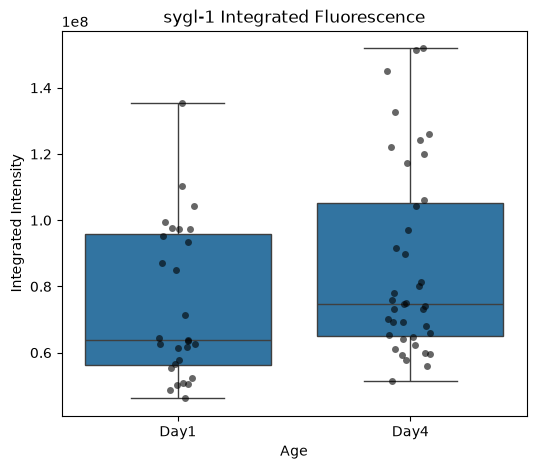

In [36]:
# Figure 3: Integrated Intensity
plt.figure(figsize=(6,5))

sns.boxplot(
    data=df,
    x="Age",
    y="Integrated_Intensity"
)

sns.stripplot(
    data=df,
    x="Age",
    y="Integrated_Intensity",
    color="black",
    alpha=0.6
)

plt.title("sygl-1 Integrated Fluorescence")
plt.ylabel("Integrated Intensity")

plt.show()

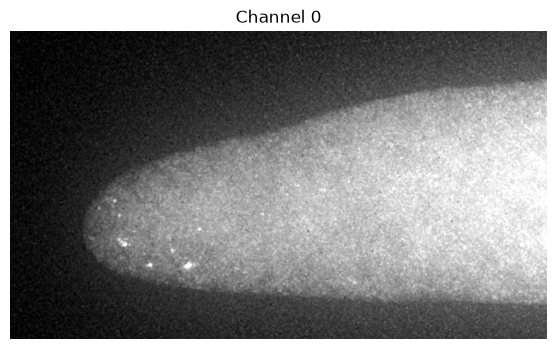

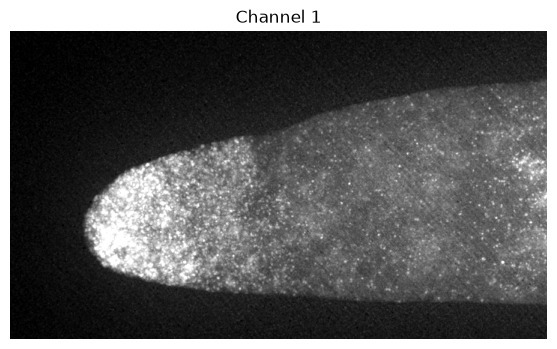

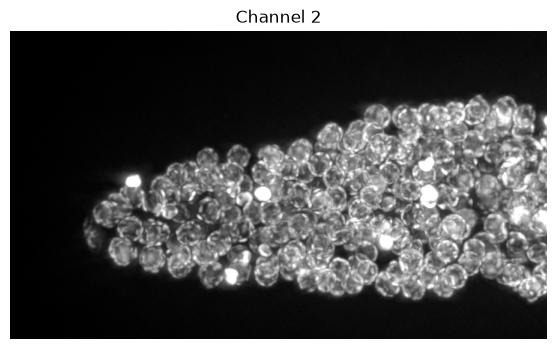

In [37]:
# Improved pipeline for determining DAPI channel
import numpy as np
import matplotlib.pyplot as plt

for c in range(3):

    proj = np.max(img[:,:,:,c], axis=0)

    low, high = np.percentile(proj,(1,99))

    plt.figure(figsize=(8,4))
    plt.imshow(proj,
               cmap="gray",
               vmin=low,
               vmax=high)

    plt.title(f"Channel {c}")
    plt.axis("off")

    plt.show()

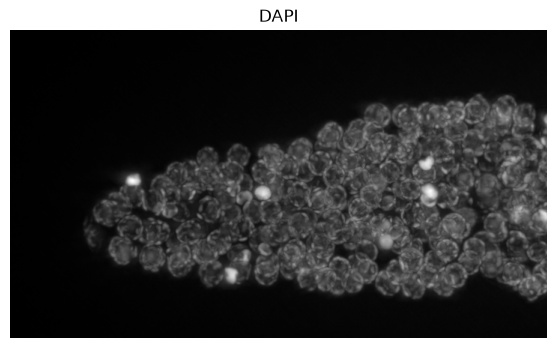

In [38]:
# Extract DAPI and sygl-1
import numpy as np
import matplotlib.pyplot as plt

dapi = np.max(img[:,:,:,2], axis=0)

sygl1 = np.max(img[:,:,:,1], axis=0)

plt.figure(figsize=(10,4))
plt.imshow(dapi, cmap="gray")
plt.title("DAPI")
plt.axis("off")
plt.show()


In [39]:
# checking image width
print(dapi.shape)

(411, 717)


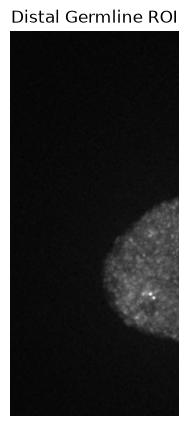

In [40]:
roi_width = 180

roi_dapi = dapi[:, :roi_width]
roi_sygl1 = sygl1[:, :roi_width]

plt.figure(figsize=(8,5))
plt.imshow(roi_sygl1, cmap="gray")
plt.title("Distal Germline ROI")
plt.axis("off")
plt.show()

In [41]:
# Measure Only the Distal Region
mean_intensity_roi = np.mean(roi_sygl1)

integrated_intensity_roi = np.sum(roi_sygl1)

print("ROI Mean:", mean_intensity_roi)
print("ROI Integrated:", integrated_intensity_roi)

ROI Mean: 262.62818329278184
ROI Integrated: 19429233


In [42]:
# Count Spots Only in the Distal Germline
from skimage.feature import blob_log

roi_spots = blob_log(
    roi_sygl1,
    min_sigma=1,
    max_sigma=3,
    num_sigma=10,
    threshold=0.001
)

print("ROI Spot Count:", len(roi_spots))

ROI Spot Count: 104


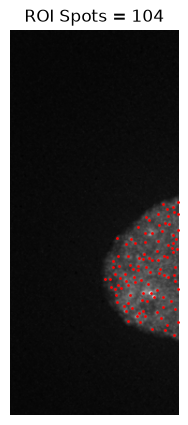

In [43]:
#  Detection Verification
plt.figure(figsize=(8,5))

plt.imshow(roi_sygl1, cmap="gray")

for y,x,r in roi_spots:
    plt.plot(x,y,'r.',markersize=2)

plt.title(f"ROI Spots = {len(roi_spots)}")

plt.axis("off")
plt.show()

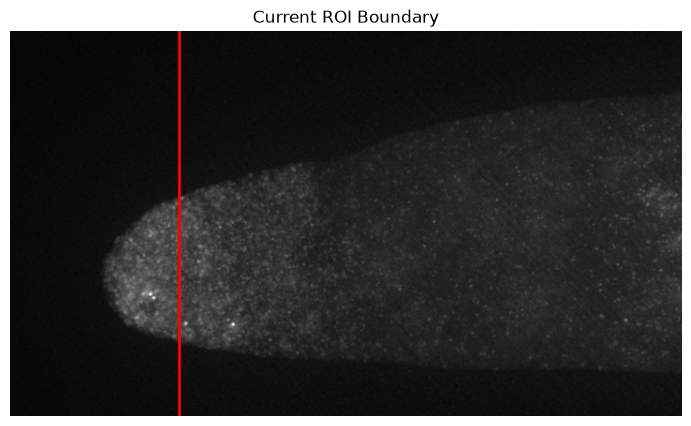

In [44]:
plt.figure(figsize=(10,5))
plt.imshow(sygl1, cmap="gray")

plt.axvline(x=180, color="red", linewidth=2)

plt.title("Current ROI Boundary")
plt.axis("off")
plt.show()

In [45]:
# looking for distal sygl-1 expression domain
# New function implementation
def analyze_image_roi(filepath):

    img = imread(filepath)

    sygl1 = np.max(img[:,:,:,1], axis=0)

    roi = sygl1[:, :180]

    mean_intensity = np.mean(roi)

    integrated_intensity = np.sum(roi)

    spots = blob_log(
        roi,
        min_sigma=1,
        max_sigma=3,
        num_sigma=10,
        threshold=0.001
    )

    spot_count = len(spots)

    return mean_intensity, integrated_intensity, spot_count

In [46]:
file = os.path.join(day1_folder, day1_files[0])

mean_i, integrated_i, spots = analyze_image_roi(file)

print(mean_i)
print(integrated_i)
print(spots)

262.62818329278184
19429233
104


In [47]:
# Processing all image with ROI
results_roi = []

In [48]:
# day1
for file in day1_files:

    path = os.path.join(day1_folder, file)

    mean_i, integrated_i, spots = analyze_image_roi(path)

    results_roi.append({
        "Image": file,
        "Age": "Day1",
        "Mean_Intensity": mean_i,
        "Integrated_Intensity": integrated_i,
        "Spot_Count": spots
    })

print("Finished ROI Day1")

Finished ROI Day1


In [49]:
# day4
for file in day4_files:

    path = os.path.join(day4_folder, file)

    mean_i, integrated_i, spots = analyze_image_roi(path)

    results_roi.append({
        "Image": file,
        "Age": "Day4",
        "Mean_Intensity": mean_i,
        "Integrated_Intensity": integrated_i,
        "Spot_Count": spots
    })

print("Finished ROI Day4")

Finished ROI Day4


In [50]:
# ROI dataframe
df_roi = pd.DataFrame(results_roi)

df_roi.head()

,Image,Age,Mean_Intensity,Integrated_Intensity,Spot_Count
0,N2 day1 image 01.tif,Day1,262.628183,19429233,104
1,N2 day1 image 02.tif,Day1,269.897600,21813124,175
2,N2 day1 image 03.tif,Day1,258.086400,17838932,162
3,N2 day1 image 04.tif,Day1,313.830954,24403495,237
4,N2 day1 image 05.tif,Day1,256.733600,21211330,130


In [51]:
df_roi.shape

(67, 5)

In [52]:
day1_roi = df_roi[df_roi["Age"]=="Day1"]

day4_roi = df_roi[df_roi["Age"]=="Day4"]

In [53]:
# sygl-1 spot count
from scipy.stats import ttest_ind

t,p = ttest_ind(
    day1_roi["Spot_Count"],
    day4_roi["Spot_Count"]
)

print("ROI Spot Count p =",p)

ROI Spot Count p = 0.747385866749142


In [54]:
# Mean Intensity
t,p = ttest_ind(
    day1_roi["Mean_Intensity"],
    day4_roi["Mean_Intensity"]
)

print("ROI Mean Intensity p =",p)

ROI Mean Intensity p = 0.4279599056428548


In [55]:
# Integrated Intensity
t,p = ttest_ind(
    day1_roi["Integrated_Intensity"],
    day4_roi["Integrated_Intensity"]
)

print("ROI Integrated Intensity p =",p)


ROI Integrated Intensity p = 0.5092237361596244
